## Docker Compose Tutorial

#### Author           : Dr. Sujoy Kumar Biswas, Ph.D., M.Tech.
####                   Head of Research & Innovation
####                   IDEAS - Technology Innovation Hub, Indian Statistical Institute (ISI), Kolkata
####                   Founder, AIMP LABS (www.aimplabs.org)

#### Target Audience  : IDEAS-TIH Research & Engineering Interns (Autumn 2026)
--------------------------------------------------------------------------------

Docker Compose, is especially useful for managing services when containers run. Making training and streamlit app as separate services will make this distinction much easier to understand.

#### 1. Recommended architecture
Instead of a multistage build, use one Docker image and two Compose services.

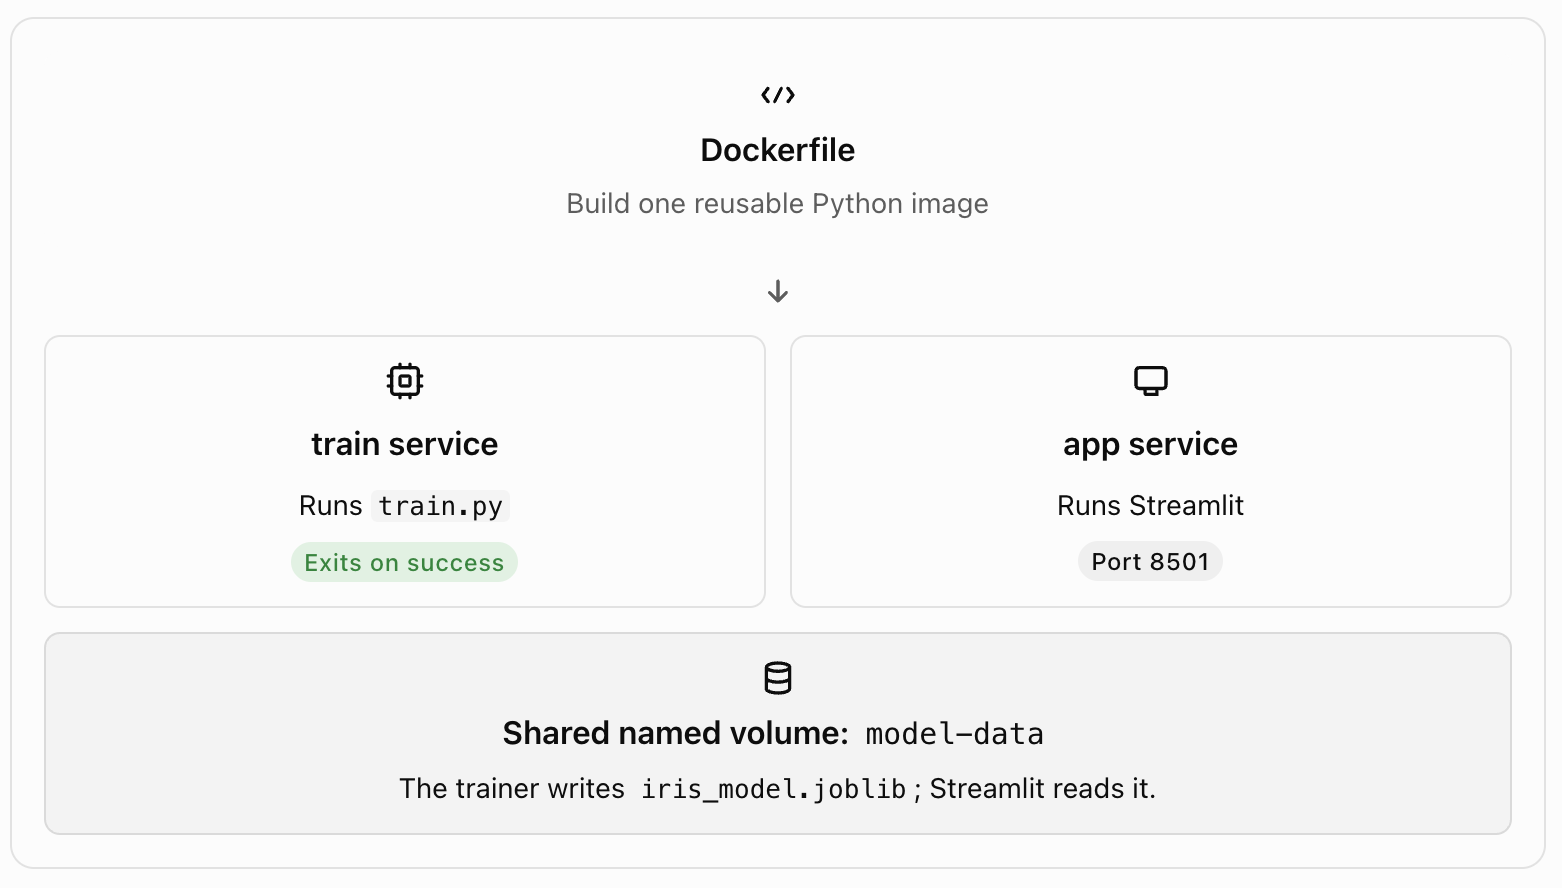

Compose can wait for the training service to finish successfully before starting the app, using depends_on with service_completed_successfully. The named volume makes the model accessible to both containers without copying it through the hos

#### 2. Project directory
Create the following directory:

```
iris-compose-demo/
├── Dockerfile
├── compose.yaml
├── requirements.txt
├── train.py
└── app.py
```

A. requirements.txt
```
numpy
scikit-learn
joblib
streamlit
```

For a production project, pin the package versions to improve reproducibility. For this introductory demonstration, keeping the list simple is reasonable.

B. train.py
The trainer saves the model into /models, which will be the shared Docker volume.

C. app.py
The Streamlit application loads the trained artifact from the shared volume.

D. Dockerfile
Notice that this is now a single-stage Dockerfile. It packages the scripts and dependencies into one reusable image.

The trainer service will override the default command to run python train.py. The app service uses the default Streamlit command. This is a useful moment to teach the interns the difference between CMD in a Dockerfile and command in Compose.

E. compose.yaml
This is the central discussion point.

| Compose configuration | Concept demonstrated |
|----------------------|----------------------|
| `services` | Define the containers that make up the application |
| `image` and `build` | Build an image that can be reused by multiple services |
| `command` | Override the image's default command for training |
| `volumes` | Share the trained model between containers |
| `:ro` | Mount the model volume read-only for inference |
| `depends_on` | Wait for training to finish successfully before starting inference |
| `ports` | Make Streamlit accessible from the host |

This acts as a memory sheet for Docker Compose basics — good for beginners to quickly grasp the key concepts.

#### 3. Run the complete demonstration

Open a terminal in `iris-compose-demo/.`

Step 1 — Validate the Compose configuration
`docker compose config`

Explain that Compose reads the YAML and resolves the configuration before starting containers.

Step 2 — Build the image and start both services
`docker compose up --build` 


The sequence should be:
1. Docker builds the iris-compose-demo:latest image.
2. Compose starts the train service.
3. The trainer fits Logistic Regression and saves /models/iris_model.joblib.
4. The trainer exits successfully.
5. Compose starts the Streamlit app service.
6. The app loads the model and serves predictions.

The model is not stored in the image itself in this design; it is stored in the named volume. This also illustrates the distinction between an image, a container, and persistent data.

Step 3 — Open the app
Go to: http://localhost:8501

Change the Iris measurements and click Predict.

Step 4 — Inspect the services
In a second terminal:
`docker compose ps -a`

Note that `train` should be exited successfully, while app should remain running.
Inspect training logs:
`docker compose logs train`

Inspect the Streamlit logs:
`docker compose logs -f app`

You can also inspect the volume:
`docker volume ls`

Compose normally prefixes the named volume with the project name, so its actual name may resemble `iris-compose-demo_model-data`.

Step 5 — Stop and clean up
Press Ctrl+C in the terminal running Compose, then run:
`docker compose down`


This removes the containers but ordinarily preserves the named volume. To also delete the saved model volume:
`docker compose down -v`

Use the second command only when you want to start the exercise again with no saved model.

#### 4. Demonstrate retraining

This is a nice extension because it shows that model training and inference are independently runnable services.
While the app is running, execute:
`docker compose run --rm train`

This runs the training command again and updates the model in the shared volume.

Then restart Streamlit so it reloads the new model:
`docker compose restart app`

The app loads the model when it starts. The explicit restart is important because st.cache_resource keeps the loaded model in memory during the app's lifetime.

#### 5. Is this better than multistage Docker builds?

The difference to emphasize is that multistage builds organize image construction; Compose organizes running services. They solve different problems and are complementary rather than competing approaches. 
